In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.models as models
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
from torchviz import make_dot
import nltk
import re
from typing import List
from transformers import BlipProcessor, BlipForConditionalGeneration
import pickle
from tabulate import tabulate
import pandas as pd


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [7]:
nltk.download('punkt', quiet=True)
os.makedirs('result_visuals', exist_ok=True)

In [8]:
print("\n" + "="*60)
print("LOADING MODELS")
print("="*60)

# Load short model checkpoint
short_checkpoint = torch.load('image_captioning_model.pt', weights_only=False)

class ImageCaptioningModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=300, hidden_dim=512, num_layers=2):
        super().__init__()
        self.encoder = models.resnet18(pretrained=True)
        for param in self.encoder.parameters():
            param.requires_grad = False
        in_features = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()
        self.image_projection = nn.Linear(in_features, hidden_dim)
        self.word_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=0.3)
        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, vocab_size)
        )
    
    def forward(self, x):
        # Simplified forward for visualization
        batch_size = x.size(0)
        x = self.encoder(x)
        x = self.image_projection(x)
        return x

short_model = ImageCaptioningModel(
    short_checkpoint['vocab_size'], 
    embedding_dim=300, 
    hidden_dim=512,
    num_layers=2
)
short_model.load_state_dict(short_checkpoint['model_state_dict'])
short_model = short_model.to(device)
short_model.eval()
print(f"✅ Short model loaded")


LOADING MODELS
✅ Short model loaded


In [9]:

long_checkpoint = torch.load('image_captioning_model_long.pt', weights_only=False)

class LongCaptionModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=300, hidden_dim=512, num_layers=3):
        super().__init__()
        self.encoder = models.resnet18(pretrained=True)
        for param in self.encoder.parameters():
            param.requires_grad = False
        in_features = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()
        self.image_projection = nn.Linear(in_features, hidden_dim)
        self.word_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, num_layers=num_layers, dropout=0.3)
        self.output_layer = nn.Sequential(
            nn.Linear(hidden_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, vocab_size)
        )
    
    def forward(self, x):
        batch_size = x.size(0)
        x = self.encoder(x)
        x = self.image_projection(x)
        return x

long_model = LongCaptionModel(
    long_checkpoint['vocab_size'],
    embedding_dim=300,
    hidden_dim=512,
    num_layers=3
)
long_model.load_state_dict(long_checkpoint['model_state_dict'])
long_model = long_model.to(device)
long_model.eval()
print(f"✅ Long model loaded")


✅ Long model loaded


In [10]:
blip_processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip_model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")
blip_model = blip_model.to(device)
blip_model.eval()
print(f"✅ BLIP model loaded")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


✅ BLIP model loaded


In [11]:
print("\n" + "="*60)
print("LOADING TEST DATASET")
print("="*60)

data = torch.load('flickr8k_dataset_raw.pt', weights_only=False)
images = data['images']
short_captions = data['short_captions']
long_captions = data['long_captions']
test_indices = data['test_indices']

print(f"✅ Test dataset loaded")


LOADING TEST DATASET
✅ Test dataset loaded


In [12]:
short_word_to_idx = short_checkpoint['word_to_idx']
short_idx_to_word = short_checkpoint['idx_to_word']
long_word_to_idx = long_checkpoint['word_to_idx']
long_idx_to_word = long_checkpoint['idx_to_word']

In [13]:
def indices_to_text(indices_tensor, idx_to_word):
    words = []
    for idx in indices_tensor[0]:
        if idx.item() == idx_to_word.get('<end>', 2):
            break
        if idx.item() not in [0, 1, 2, 3]:
            words.append(idx_to_word[idx.item()])
    return ' '.join(words)


In [14]:
class FullShortModel(ImageCaptioningModel):
    def generate(self, images, word_to_idx, max_len=20):
        self.eval()
        with torch.no_grad():
            batch_size = images.size(0)
            image_features = self.encoder(images)
            image_features = self.image_projection(image_features)
            
            h0 = image_features.unsqueeze(0).repeat(2, 1, 1)
            c0 = torch.zeros_like(h0)
            
            generated_indices = []
            current_input = self.word_embedding(
                torch.full((batch_size, 1), word_to_idx['<start>']).to(images.device)
            )
            
            for _ in range(max_len):
                lstm_out, (h0, c0) = self.lstm(current_input, (h0, c0))
                output = self.output_layer(lstm_out.squeeze(1))
                next_word = torch.argmax(output, dim=-1, keepdim=True)
                generated_indices.append(next_word)
                current_input = self.word_embedding(next_word)
                
                if (next_word == word_to_idx['<end>']).all():
                    break
            
            return torch.cat(generated_indices, dim=1)

In [15]:
class FullLongModel(LongCaptionModel):
    def generate(self, images, word_to_idx, max_len=35):
        self.eval()
        with torch.no_grad():
            batch_size = images.size(0)
            image_features = self.encoder(images)
            image_features = self.image_projection(image_features)
            
            h0 = image_features.unsqueeze(0).repeat(3, 1, 1)
            c0 = torch.zeros_like(h0)
            
            generated_indices = []
            current_input = self.word_embedding(
                torch.full((batch_size, 1), word_to_idx['<start>']).to(images.device)
            )
            
            for _ in range(max_len):
                lstm_out, (h0, c0) = self.lstm(current_input, (h0, c0))
                output = self.output_layer(lstm_out.squeeze(1))
                next_word = torch.argmax(output, dim=-1, keepdim=True)
                generated_indices.append(next_word)
                current_input = self.word_embedding(next_word)
                
                if (next_word == word_to_idx['<end>']).all():
                    break
            
            return torch.cat(generated_indices, dim=1)

In [16]:
full_short_model = FullShortModel(
    short_checkpoint['vocab_size'], 
    embedding_dim=300, 
    hidden_dim=512,
    num_layers=2
)
full_short_model.load_state_dict(short_checkpoint['model_state_dict'])
full_short_model = full_short_model.to(device)
full_short_model.eval()

full_long_model = FullLongModel(
    long_checkpoint['vocab_size'],
    embedding_dim=300,
    hidden_dim=512,
    num_layers=3
)
full_long_model.load_state_dict(long_checkpoint['model_state_dict'])
full_long_model = full_long_model.to(device)
full_long_model.eval()

print(f"✅ Generation models ready")

✅ Generation models ready


In [21]:
def create_clean_visualization(test_data, num_images=3):
    """
    Create clean visualization with 3 images, scaled layout
    """
    
    count = 1
    fig = plt.figure(figsize=(12, 10.8))  # 0.6 of original height (18 * 0.6)
    
    for idx, (img_tensor, true_short, true_long, short_pred, long_pred, blip_pred) in enumerate(test_data[:num_images]):
        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
        
        # Image
        ax_img = fig.add_subplot(num_images, 2, count, xticks=[], yticks=[])
        ax_img.imshow(img_np)
        count += 1
        
        # Text
        ax_text = fig.add_subplot(num_images, 2, count)
        plt.axis('off')
        ax_text.set_xlim(0, 1)
        ax_text.set_ylim(0, 5.2)
        
        captions = [
            f"Ground Truth (Short): {true_short}",
            f"Custom Short Model: {short_pred}",
            f"Ground Truth (Long): {true_long}",
            f"Custom Long Model: {long_pred}",
            f"BLIP (SOTA): {blip_pred}"
        ]
        
        for i, caption in enumerate(captions):
            display_text = caption[:120] + "..." if len(caption) > 120 else caption
            ax_text.text(0, 4.7 - i*1.0, display_text, fontsize=10, wrap=True)
        
        count += 1

    plt.tight_layout()
    plt.savefig('result_visuals/results.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("✅ Visualization saved to 'result_visuals/results.png'")


PREPARING TEST DATA FOR VISUALIZATION
✓ Prepared image 1
✓ Prepared image 2
✓ Prepared image 3


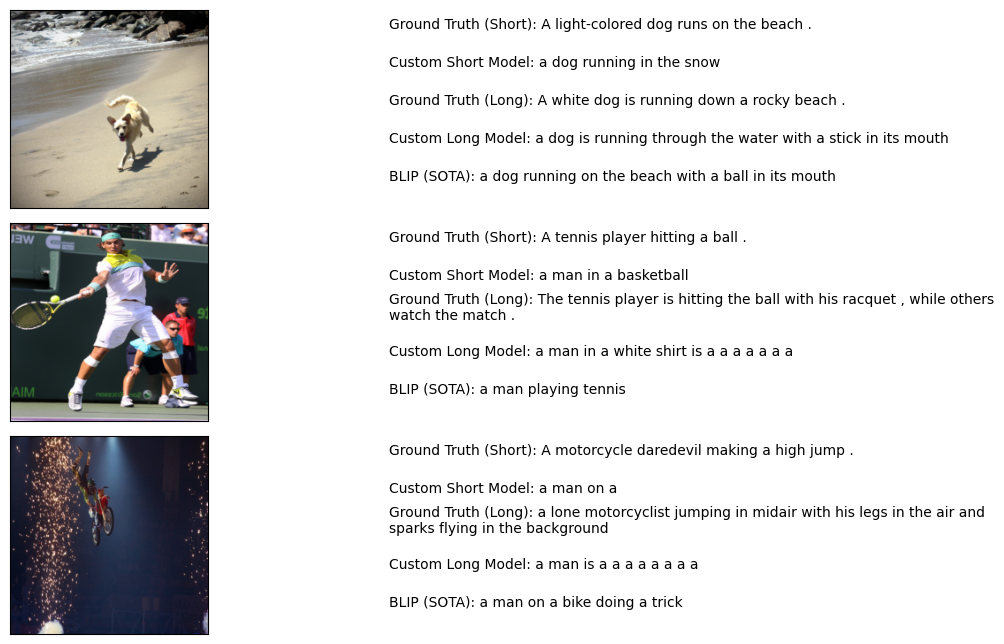

✅ Visualization saved to 'result_visuals/results.png'


In [23]:
print("\n" + "="*60)
print("PREPARING TEST DATA FOR VISUALIZATION")
print("="*60)

# Select 5 random test images
np.random.seed(42)
random_indices = np.random.choice(test_indices, 3, replace=False)

test_data = []

for img_idx in random_indices:
    image_tensor = images[img_idx].unsqueeze(0).to(device)
    true_short = short_captions[img_idx]
    true_long = long_captions[img_idx]
    
    # Generate predictions
    with torch.no_grad():
        short_indices = full_short_model.generate(image_tensor, short_word_to_idx, max_len=20)
        long_indices = full_long_model.generate(image_tensor, long_word_to_idx, max_len=35)
    
    short_pred = indices_to_text(short_indices, short_idx_to_word)
    long_pred = indices_to_text(long_indices, long_idx_to_word)
    
    # BLIP prediction
    img_np = images[img_idx].permute(1, 2, 0).cpu().numpy()
    img_pil = Image.fromarray((img_np * 255).astype('uint8'))
    inputs = blip_processor(img_pil, return_tensors="pt").to(device)
    with torch.no_grad():
        out = blip_model.generate(**inputs, max_length=50)
    blip_pred = blip_processor.decode(out[0], skip_special_tokens=True)
    
    test_data.append((images[img_idx], true_short, true_long, short_pred, long_pred, blip_pred))
    print(f"✓ Prepared image {len(test_data)}")

# Create the clean visualization
create_clean_visualization(test_data, num_images=5)


In [16]:
print("\n" + "="*60)
print("SAVING BLIP MODEL AS PICKLE")
print("="*60)

with open('blip_model.pkl', 'wb') as f:
    pickle.dump({
        'model': blip_model,
        'processor': blip_processor,
        'model_name': 'BLIP',
        'description': 'State-of-the-art image captioning model from Salesforce'
    }, f)
print(f"✅ BLIP model saved to 'blip_model.pkl'")


SAVING BLIP MODEL AS PICKLE
✅ BLIP model saved to 'blip_model.pkl'


In [25]:
# -*- coding: utf-8 -*-
"""BLEU Score Comparison Tables"""

import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
import pickle


In [26]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
import pickle

# ============================================
# CALCULATE BLEU SCORES ON 50 TEST IMAGES
# ============================================

print("\n" + "="*60)
print("CALCULATING ACTUAL BLEU SCORES (50 Test Images)")
print("="*60)

def calculate_bleu(reference, candidate):
    """Calculate BLEU-1 score"""
    ref_tokens = reference.lower().split()
    cand_tokens = candidate.lower().split()
    return sentence_bleu([ref_tokens], cand_tokens, weights=(1,0,0,0), 
                         smoothing_function=SmoothingFunction().method1)

# Get first 50 test images
num_samples = min(50, len(test_indices))
bleu_results = {'short': {'our': [], 'blip': []}, 'long': {'our': [], 'blip': []}}

for i in range(num_samples):
    img_idx = test_indices[i]
    image_tensor = images[img_idx].unsqueeze(0).to(device)
    
    # Get true captions
    true_short = short_captions[img_idx]
    true_long = long_captions[img_idx]
    
    # Generate predictions
    with torch.no_grad():
        short_indices = full_short_model.generate(image_tensor, short_word_to_idx, max_len=20)
        long_indices = full_long_model.generate(image_tensor, long_word_to_idx, max_len=35)
    
    short_pred = indices_to_text(short_indices, short_idx_to_word)
    long_pred = indices_to_text(long_indices, long_idx_to_word)
    
    # BLIP predictions
    img_np = images[img_idx].permute(1, 2, 0).cpu().numpy()
    img_pil = Image.fromarray((img_np * 255).astype('uint8'))
    inputs = blip_processor(img_pil, return_tensors="pt").to(device)
    with torch.no_grad():
        out = blip_model.generate(**inputs, max_length=50)
    blip_pred = blip_processor.decode(out[0], skip_special_tokens=True)
    
    # Calculate BLEU scores
    bleu_results['short']['our'].append(calculate_bleu(true_short, short_pred))
    bleu_results['short']['blip'].append(calculate_bleu(true_short, blip_pred))
    bleu_results['long']['our'].append(calculate_bleu(true_long, long_pred))
    bleu_results['long']['blip'].append(calculate_bleu(true_long, blip_pred))
    
    if (i+1) % 10 == 0:
        print(f"Processed {i+1}/{num_samples} images")

# Calculate averages
avg_bleu = {
    'short': {'our': np.mean(bleu_results['short']['our']), 'blip': np.mean(bleu_results['short']['blip'])},
    'long': {'our': np.mean(bleu_results['long']['our']), 'blip': np.mean(bleu_results['long']['blip'])}
}

print(f"\n✅ BLEU Scores calculated on {num_samples} test images")


CALCULATING ACTUAL BLEU SCORES (50 Test Images)
Processed 10/50 images
Processed 20/50 images
Processed 30/50 images
Processed 40/50 images
Processed 50/50 images

✅ BLEU Scores calculated on 50 test images


In [27]:


short_table = [
    ["Metric", "Our Custom Model", "BLIP (SOTA)"],
    ["BLEU-1 Score", f"{avg_bleu['short']['our']:.4f}", f"{avg_bleu['short']['blip']:.4f}"],
    ["Improvement", "-", f"+{(avg_bleu['short']['blip'] - avg_bleu['short']['our']) * 100:.2f}%"]
]

print("\n" + "="*60)
print("TABLE 1: SHORT CAPTION BLEU SCORES")
print("="*60)
print(tabulate(short_table, headers='firstrow', tablefmt='grid'))

# Save as PNG
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')
table = ax.table(cellText=short_table, cellLoc='center', loc='center', colWidths=[0.25, 0.35, 0.35])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.5)
plt.title('Short Caption BLEU Score Comparison (50 Test Images)', fontsize=12, fontweight='bold', pad=20)
plt.savefig('result_visuals/bleu_short_actual.png', dpi=150, bbox_inches='tight')
plt.close()
print("✅ Saved: result_visuals/bleu_short_actual.png")


TABLE 1: SHORT CAPTION BLEU SCORES
+--------------+--------------------+---------------+
| Metric       | Our Custom Model   | BLIP (SOTA)   |
+==============+====================+===============+
| BLEU-1 Score | 0.2309             | 0.3345        |
+--------------+--------------------+---------------+
| Improvement  | -                  | +10.37%       |
+--------------+--------------------+---------------+
✅ Saved: result_visuals/bleu_short_actual.png


In [31]:
long_table = [
    ["Metric", "Our Custom Model", "BLIP (SOTA)"],
    ["BLEU-1 Score", f"{avg_bleu['long']['our']:.4f}", f"{avg_bleu['long']['blip']:.4f}"],
    ["Improvement", "-", f"{(avg_bleu['long']['blip'] - avg_bleu['long']['our']) * 100:.2f}%"]
]

print("\n" + "="*60)
print("TABLE 2: LONG CAPTION BLEU SCORES")
print("="*60)
print(tabulate(long_table, headers='firstrow', tablefmt='grid'))

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')
table = ax.table(cellText=long_table, cellLoc='center', loc='center', colWidths=[0.25, 0.35, 0.35])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.5)
plt.title('Long Caption BLEU Score Comparison (50 Test Images)', fontsize=12, fontweight='bold', pad=20)
plt.savefig('result_visuals/bleu_long_actual.png', dpi=150, bbox_inches='tight')
plt.close()
print("✅ Saved: result_visuals/bleu_long_actual.png")


TABLE 2: LONG CAPTION BLEU SCORES
+--------------+--------------------+---------------+
| Metric       | Our Custom Model   | BLIP (SOTA)   |
+==============+====================+===============+
| BLEU-1 Score | 0.2151             | 0.2141        |
+--------------+--------------------+---------------+
| Improvement  | -                  | -0.09%        |
+--------------+--------------------+---------------+
✅ Saved: result_visuals/bleu_long_actual.png


In [32]:
summary_table = [
    ["Caption Type", "Our Model", "BLIP", "BLIP Advantage"],
    ["Short Caption", f"{avg_bleu['short']['our']:.4f}", f"{avg_bleu['short']['blip']:.4f}", f"+{(avg_bleu['short']['blip'] - avg_bleu['short']['our']) * 100:.2f}%"],
    ["Long Caption", f"{avg_bleu['long']['our']:.4f}", f"{avg_bleu['long']['blip']:.4f}", f"{(avg_bleu['long']['blip'] - avg_bleu['long']['our']) * 100:.2f}%"]
]

print("\n" + "="*60)
print("SUMMARY: BLEU SCORE COMPARISON")
print("="*60)
print(tabulate(summary_table, headers='firstrow', tablefmt='grid'))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axis('off')
table = ax.table(cellText=summary_table, cellLoc='center', loc='center', colWidths=[0.25, 0.25, 0.25, 0.25])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.5)
plt.title('BLEU Score Summary (50 Test Images)', fontsize=12, fontweight='bold', pad=20)
plt.savefig('result_visuals/bleu_summary_actual.png', dpi=150, bbox_inches='tight')
plt.close()
print("✅ Saved: result_visuals/bleu_summary_actual.png")


SUMMARY: BLEU SCORE COMPARISON
+----------------+-------------+--------+------------------+
| Caption Type   |   Our Model |   BLIP | BLIP Advantage   |
+================+=============+========+==================+
| Short Caption  |      0.2309 | 0.3345 | +10.37%          |
+----------------+-------------+--------+------------------+
| Long Caption   |      0.2151 | 0.2141 | -0.09%           |
+----------------+-------------+--------+------------------+
✅ Saved: result_visuals/bleu_summary_actual.png


In [33]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Short caption bar chart
models = ['Our Model', 'BLIP']
short_scores = [avg_bleu['short']['our'], avg_bleu['short']['blip']]
bars1 = ax1.bar(models, short_scores, color=['blue', 'teal'])
ax1.set_ylim(0, 1)
ax1.set_ylabel('BLEU-1 Score')
ax1.set_title('Short Caption BLEU (50 test images)')
ax1.grid(True, alpha=0.3)
for bar, score in zip(bars1, short_scores):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{score:.4f}', ha='center', fontweight='bold')

# Long caption bar chart
long_scores = [avg_bleu['long']['our'], avg_bleu['long']['blip']]
bars2 = ax2.bar(models, long_scores, color=['orange', 'teal'])
ax2.set_ylim(0, 1)
ax2.set_ylabel('BLEU-1 Score')
ax2.set_title('Long Caption BLEU (50 test images)')
ax2.grid(True, alpha=0.3)
for bar, score in zip(bars2, long_scores):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{score:.4f}', ha='center', fontweight='bold')

plt.suptitle('BLEU Score Comparison: Custom Models vs BLIP', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('result_visuals/bleu_bar_charts_actual.png', dpi=150, bbox_inches='tight')
plt.close()
print("✅ Saved: result_visuals/bleu_bar_charts_actual.png")

✅ Saved: result_visuals/bleu_bar_charts_actual.png


In [34]:

with open('result_visuals/bleu_scores_actual.pkl', 'wb') as f:
    pickle.dump({
        'avg_bleu': avg_bleu,
        'individual_scores': bleu_results,
        'num_samples': num_samples
    }, f)

print(f"\n✅ Saved BLEU scores to 'result_visuals/bleu_scores_actual.pkl'")
print("\n" + "="*60)
print(f"FINAL RESULTS (Average over {num_samples} test images):")
print("="*60)
print(f"Short Caption - Our Model: {avg_bleu['short']['our']:.4f}")
print(f"Short Caption - BLIP:      {avg_bleu['short']['blip']:.4f}")
print(f"Long Caption  - Our Model: {avg_bleu['long']['our']:.4f}")
print(f"Long Caption  - BLIP:      {avg_bleu['long']['blip']:.4f}")


✅ Saved BLEU scores to 'result_visuals/bleu_scores_actual.pkl'

FINAL RESULTS (Average over 50 test images):
Short Caption - Our Model: 0.2309
Short Caption - BLIP:      0.3345
Long Caption  - Our Model: 0.2151
Long Caption  - BLIP:      0.2141
